# FIG2 — Automatic segmentation compared with ground truth

Inputs: `images_clean_*.csv`, `labels_clean_*.csv`, and `../for_uunet/images_preds_NEW.csv`. For each center, all false positives are retained, and for each case the overlapping predictions with the maximum Dice score are kept. The saved plot output from the source notebook is preserved.


In [ ]:
from pathlib import Path
import pandas as pd

# Match the feature_tables_FINAL_2D folder selected in the source notebook.
base = Path("feature_tables_FINAL_2D") / "T2_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original__ADC_lesion_iqr_zscore_stats2D_apply2D_lesionsrc_original_BIN_16"
images_path = next(base.glob("images_clean_*.csv"))
labels_path = next(base.glob("labels_clean_*.csv"))
images_all = pd.read_csv(images_path)
labels_all = pd.read_csv(labels_path)

# Recreate validation rows and labels for Novara and Torino.
IDX_US = 876
IDX_PICAI = 425
IDX_NOV = 77
IDX_SPLIT = IDX_US + IDX_PICAI
images_nov = images_all.iloc[IDX_SPLIT:IDX_SPLIT + IDX_NOV].reset_index(drop=True)
images_tor = images_all.iloc[IDX_SPLIT + IDX_NOV:].reset_index(drop=True)
labels_val = labels_all.iloc[IDX_SPLIT:].reset_index(drop=True)
labels_nov = labels_val.iloc[:IDX_NOV][["GG"]].reset_index(drop=True)
labels_tor = labels_val.iloc[IDX_NOV:][["GG"]].reset_index(drop=True)

if len(images_nov) != len(labels_nov) or len(images_tor) != len(labels_tor):
    raise ValueError("GT image and label rows do not align with the configured cohort splits.")

# Load saved predictions; the first 77 rows are assigned to Novara as in the source.
images_val_pred = pd.read_csv("../for_uunet/images_preds_NEW.csv")
images_val_pred.loc[images_val_pred["idx"] < IDX_NOV, "center"] = "Novara"

def filter_center_predictions(center, gt_images, gt_labels):
    gt_images = gt_images.copy()
    gt_images["GG"] = gt_labels["GG"].to_numpy()

    center_predictions = images_val_pred.loc[images_val_pred["center"] == center].copy()
    case_order = center_predictions["case_id"].drop_duplicates().to_numpy()
    gt_for_predictions = (
        gt_images.set_index("case_id")
        .loc[case_order]
        .reset_index()
    )
    order = gt_for_predictions.sort_values("GG")["case_id"]
    df = (
        center_predictions.set_index("case_id")
        .loc[order]
        .reset_index()
    )

    max_dice_per_case = (
        df.loc[df["overlap_nonzero"]]
        .groupby("case_id")["dice_vs_gt_global"]
        .max()
    )
    df["max_dice_overlap_case"] = df["case_id"].map(max_dice_per_case)
    keep = (
        ~df["overlap_nonzero"]
        | (df["dice_vs_gt_global"] == df["max_dice_overlap_case"])
    )
    return df.loc[keep].drop(columns="max_dice_overlap_case")

df_filtered_nov = filter_center_predictions("Novara", images_nov, labels_nov)
df_filtered_tor = filter_center_predictions("Torino", images_tor, labels_tor)
Path("report_FINAL").mkdir(parents=True, exist_ok=True)


# --- FIG 2

/var/folders/kf/rnqn83w16clgx6fhphk16hfm0000gn/T/ipykernel_58231/3262154037.py:214: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0,0].set_xticklabels(['','','','',''])


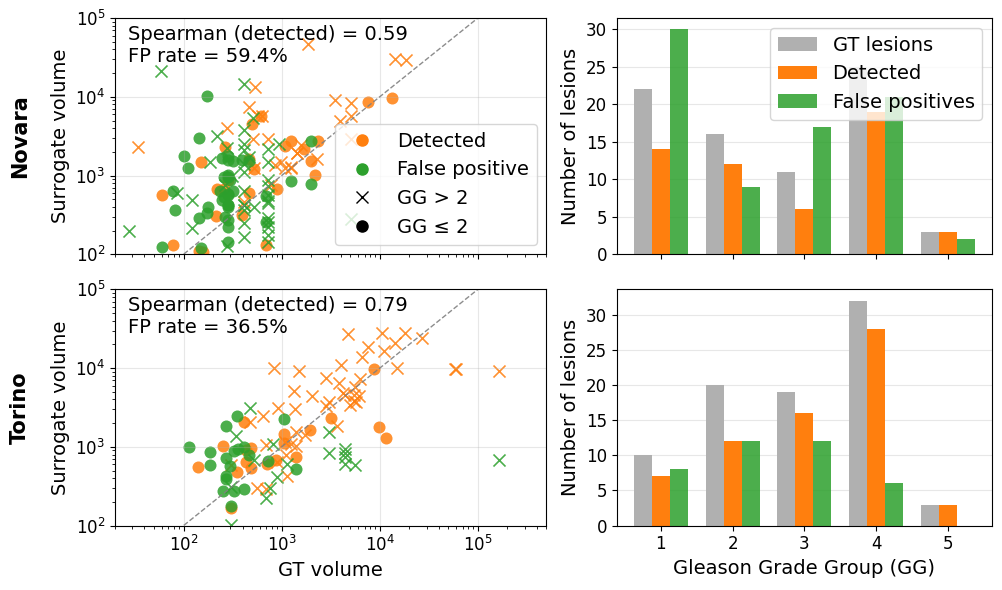

In [99]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

# ===============================
# GLOBAL FONT SIZES
# ===============================
FS_SUBTITLE = 15
FS_LABEL = 14
FS_TICK = 12
FS_TEXT = 14
FS_LEGEND = 14

# ===============================
# COLORS
# ===============================
COL_GT = "#b0b0b0"  # GT lesions
COL_DET = "#ff7f0e"  # detected / overlap
COL_FP = "#2ca02c"   # false positives

centers = [
    ("Novara", df_filtered_nov, labels_nov),
    ("Torino", df_filtered_tor, labels_tor),
]

gg_levels = np.array([1, 2, 3, 4, 5])
bar_width = 0.25

fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 6),
    gridspec_kw={"width_ratios": [1.15, 1.0]},
)

XMIN, XMAX = 2e1, 5e5
YMIN, YMAX = 1e2, 1e5

for r, (center, df, labels_gt) in enumerate(centers):

    df = df.sort_values(["GG", "case_id"]).reset_index(drop=True).copy()
    df["GG_group"] = np.where(df["GG"] <= 2, "<=2", ">2")

    # =====================================================
    # LEFT COLUMN — volume agreement
    # Color = detection status; marker = GG group
    # =====================================================
    n_fp = int((~df["overlap_nonzero"]).sum())
    n_pred = len(df)
    fp_rate = n_fp / n_pred if n_pred > 0 else np.nan

    for overlap_status, color in [(True, COL_DET), (False, COL_FP)]:
        for gg_group, marker in [("<=2", "o"), (">2", "x")]:

            sub = df[
                (df["overlap_nonzero"] == overlap_status)
                & (df["GG_group"] == gg_group)
            ]

            ax[r, 0].scatter(
                sub["gt_voxels"],
                sub["voxels"],
                color=color,
                marker=marker,
                s=75,
                alpha=0.85,
                linewidth=1.2 if marker == "x" else 0.0,
            )

    ax[r, 0].plot(
        [XMIN, XMAX],
        [XMIN, XMAX],
        "--",
        linewidth=1,
        alpha=0.9,
        color="gray",
    )

    ax[r, 0].set_xscale("log")
    ax[r, 0].set_yscale("log")
    ax[r, 0].set_xlim(XMIN, XMAX)
    ax[r, 0].set_ylim(YMIN, YMAX)

    ax[r, 0].set_xlabel("GT volume", fontsize=FS_LABEL)
    ax[r, 0].set_ylabel("Surrogate volume", fontsize=FS_LABEL)
    ax[r, 0].tick_params(axis="both", labelsize=FS_TICK)
    ax[r, 0].grid(True, alpha=0.3)

    ov = df[df["overlap_nonzero"]]
    if len(ov) >= 2:
        rho, _ = spearmanr(
            np.log10(ov["gt_voxels"]),
            np.log10(ov["voxels"]),
        )
    else:
        rho = np.nan

    ax[r, 0].text(
        0.03,
        0.97,
        f"Spearman (detected) = {rho:.2f}\n"
        f"FP rate = {fp_rate:.1%}",
        transform=ax[r, 0].transAxes,
        va="top",
        fontsize=FS_TEXT,
    )

    # =====================================================
    # RIGHT COLUMN — detection by GG
    # =====================================================
    gt_counts = (
        labels_gt["GG"]
        .value_counts()
        .reindex(gg_levels, fill_value=0)
        .sort_index()
    )

    pred_counts = (
        df.loc[df["overlap_nonzero"], "GG"]
        .value_counts()
        .reindex(gg_levels, fill_value=0)
        .sort_index()
    )

    fp_counts = (
        df.loc[~df["overlap_nonzero"], "GG"]
        .value_counts()
        .reindex(gg_levels, fill_value=0)
        .sort_index()
    )

    ax[r, 1].bar(
        gg_levels - bar_width,
        gt_counts.values,
        width=bar_width,
        label="GT lesions",
        color=COL_GT,
    )

    ax[r, 1].bar(
        gg_levels,
        pred_counts.values,
        width=bar_width,
        label="Detected",
        color=COL_DET,
    )

    ax[r, 1].bar(
        gg_levels + bar_width,
        fp_counts.values,
        width=bar_width,
        label="False positives",
        color=COL_FP,
        alpha=0.85,
    )

    ax[r, 1].set_xlabel("Gleason Grade Group (GG)", fontsize=FS_LABEL)
    ax[r, 1].set_ylabel("Number of lesions", fontsize=FS_LABEL)
    ax[r, 1].set_xticks(gg_levels)
    ax[r, 1].tick_params(axis="both", labelsize=FS_TICK)
    ax[r, 1].grid(True, axis="y", alpha=0.3)
    ax[r, 1].set_axisbelow(True)

# ===============================
# COLUMN TITLES
# ===============================
#ax[0, 0].set_title("Volume agreement", fontsize=FS_SUBTITLE)
#ax[0, 1].set_title("Detection by GG", fontsize=FS_SUBTITLE)

# ===============================
# ROW LABELS
# ===============================
for r, center in enumerate(["Novara", "Torino"]):
    ax[r, 0].text(
        -0.22,
        0.5,
        center,
        transform=ax[r, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=FS_SUBTITLE,
        fontweight="bold",
    )

# ===============================
# LEGENDS
# ===============================
legend_scatter = [
    Line2D([0], [0], marker="o", color=COL_DET, linestyle="None",
           markersize=8, label="Detected"),
    Line2D([0], [0], marker="o", color=COL_FP, linestyle="None",
           markersize=8, label="False positive"),
    Line2D([0], [0], marker="x", color="k", linestyle="None",
           markersize=8, label="GG > 2"),
    Line2D([0], [0], marker="o", color="k", linestyle="None",
           markersize=8, label="GG ≤ 2"),
]

ax[0, 0].legend(
    handles=legend_scatter,
    loc="lower right",
    frameon=True,
    fontsize=FS_LEGEND,
)

ax[0, 1].legend(
    fontsize=FS_LEGEND,
    loc="upper right",
    frameon=True,
)

ax[0,0].set_xlabel("", fontsize=FS_LABEL)
ax[0,0].set_xticklabels(['','','','',''])
ax[0,1].set_xlabel("", fontsize=FS_LABEL)
ax[0,1].set_xticklabels(['','','','',''])

plt.tight_layout()
plt.savefig("report_FINAL/automatic_segmentation_performance.pdf", bbox_inches="tight")
plt.show()